# Phân tích kết quả đấu vòng tròn

Đọc `runs/arena_matrix/games.csv` do `arena_run.ipynb` sinh ra — **không đánh lại ván nào**. Đổi `SHOW`, cặp soi chi tiết hay kiểu biểu đồ rồi chạy lại là xong.

Cách đọc: ô (hàng *A*, cột *B*) = tỉ lệ *A* thắng *B*. `result`: +1 = X (đi trước) thắng, −1 = O thắng, 0 = hoà.

In [1]:
import os
from pathlib import Path

ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / "pyproject.toml").exists())
os.chdir(ROOT)   # mọi đường dẫn tương đối tính từ gốc dự án

import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from caro.arena.stats import wilson

pd.options.display.float_format = "{:.1f}".format

## 1. Nạp dữ liệu và chọn cách xem

`SHOW = None` là xem tất cả; hoặc liệt kê tên tác tử muốn giữ (vd. bỏ L1 random để ma trận bớt nhiễu). Chỉ giữ những ván mà cả hai tác tử đều nằm trong `SHOW`.

In [2]:
OUT_DIR = Path("runs/arena_matrix")
games_all = pd.read_csv(OUT_DIR / "games.csv")
meta = json.loads((OUT_DIR / "meta.json").read_text(encoding="utf-8")) if (OUT_DIR / "meta.json").exists() else {}

# thứ tự gốc của tác tử (quyết định màu cố định); không có meta thì suy ra từ dữ liệu
all_names = list(meta.get("agents", {})) or list(dict.fromkeys(games_all[["A", "B"]].values.ravel()))

SHOW = None            # ví dụ: ["L2 rule", "L3 AB d3", "L5 v1", "L5 v2"]
names = [n for n in all_names if SHOW is None or n in SHOW]
games = games_all[games_all.A.isin(names) & games_all.B.isin(names)].reset_index(drop=True)
pairs = list(dict.fromkeys(zip(games.A, games.B)))
print(f"{len(games)} ván, {len(names)} tác tử, {len(pairs)} cặp;", "cấu hình:", {k: v for k, v in meta.items() if k != "agents"})

1500 ván, 6 tác tử, 15 cặp; cấu hình: {}


## 2. Ma trận tỉ lệ thắng

Quy kết quả về góc nhìn của tác tử hàng.

In [3]:
def outcome_for(row, agent):
    """1 thắng, 0.5 hoà, 0 thua theo góc nhìn `agent`."""
    if row.result == 0:
        return 0.5
    x_won = row.result == 1
    return float(x_won if row.agent_x == agent else not x_won)

win = pd.DataFrame(np.nan, index=names, columns=names)
draw = win.copy()
score = win.copy()
for A, B in pairs:
    g = games[(games.A == A) & (games.B == B)]
    o = np.array([outcome_for(r, A) for r in g.itertuples()])
    for r_, c_, v in ((A, B, o), (B, A, 1 - o)):
        win.loc[r_, c_] = 100 * (v == 1).mean()
        draw.loc[r_, c_] = 100 * (v == 0.5).mean()
        score.loc[r_, c_] = 100 * v.mean()

print("Tỉ lệ THẮNG (%) — hàng thắng cột"); display(win)
print("Tỉ lệ HOÀ (%)"); display(draw)

Tỉ lệ THẮNG (%) — hàng thắng cột


,L1 random,L2 rule,L3 AB d3,L4 MCTS200,L5 v1,L5 v2
L1 random,NaN,0.0,0.0,4.0,0.0,0.0
L2 rule,100.0,NaN,39.0,100.0,55.0,33.0
L3 AB d3,100.0,61.0,NaN,100.0,86.0,57.0
L4 MCTS200,96.0,0.0,0.0,NaN,0.0,0.0
L5 v1,100.0,45.0,14.0,100.0,NaN,37.0
L5 v2,100.0,65.0,42.0,100.0,62.0,NaN


Tỉ lệ HOÀ (%)


,L1 random,L2 rule,L3 AB d3,L4 MCTS200,L5 v1,L5 v2
L1 random,NaN,0.0,0.0,0.0,0.0,0.0
L2 rule,0.0,NaN,0.0,0.0,0.0,2.0
L3 AB d3,0.0,0.0,NaN,0.0,0.0,1.0
L4 MCTS200,0.0,0.0,0.0,NaN,0.0,0.0
L5 v1,0.0,0.0,0.0,0.0,NaN,1.0
L5 v2,0.0,2.0,1.0,0.0,1.0,NaN


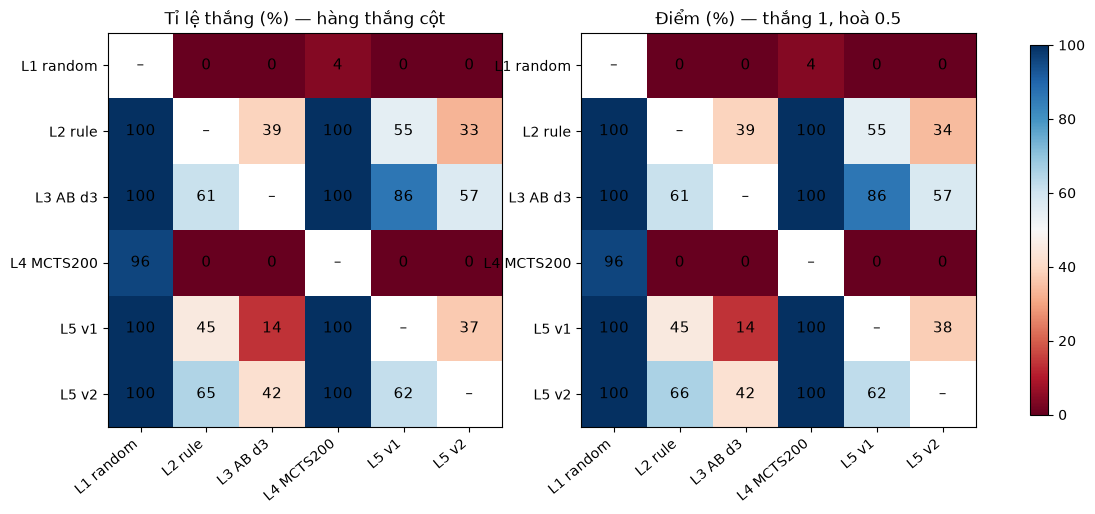

In [4]:
def heatmap(df, title, ax):
    im = ax.imshow(df.values.astype(float), cmap="RdBu", vmin=0, vmax=100)
    ax.set_xticks(range(len(df)), df.columns, rotation=40, ha="right")
    ax.set_yticks(range(len(df)), df.index)
    for i in range(len(df)):
        for j in range(len(df)):
            v = df.values[i, j]
            ax.text(j, i, "–" if np.isnan(v) else f"{v:.0f}", ha="center", va="center", fontsize=11)
    ax.set_title(title)
    return im

fig, axes = plt.subplots(1, 2, figsize=(14, 6))
heatmap(win, "Tỉ lệ thắng (%) — hàng thắng cột", axes[0])
im = heatmap(score, "Điểm (%) — thắng 1, hoà 0.5", axes[1])
fig.colorbar(im, ax=axes, shrink=0.8)
plt.savefig(OUT_DIR / "matrix.png", dpi=150, bbox_inches="tight")
plt.show()

## 3. Xếp hạng chung và khoảng tin cậy 95% (Wilson)

In [5]:
rank = []
for a in names:
    o = np.array([outcome_for(r, a) for r in games.itertuples() if a in (r.agent_x, r.agent_o)])
    w, d, l = (o == 1).sum(), (o == 0.5).sum(), (o == 0).sum()
    lo, hi = wilson(w + d / 2, len(o))
    rank.append({"tác tử": a, "ván": len(o), "thắng": w, "hoà": d, "thua": l,
                 "điểm %": 100 * o.mean(), "CI95 thấp": 100 * lo, "CI95 cao": 100 * hi})
rank = pd.DataFrame(rank).sort_values("điểm %", ascending=False).reset_index(drop=True)
rank.to_csv(OUT_DIR / "ranking.csv", index=False)
rank

,tác tử,ván,thắng,hoà,thua,điểm %,CI95 thấp,CI95 cao
0,L3 AB d3,500,404,1,95,80.9,77.2,84.1
1,L5 v2,500,369,4,127,74.2,70.2,77.8
2,L2 rule,500,327,2,171,65.6,61.3,69.6
3,L5 v1,500,296,1,203,59.3,54.9,63.5
4,L4 MCTS200,500,96,0,404,19.2,16.0,22.9
5,L1 random,500,4,0,496,0.8,0.3,2.0


## 4. Lợi thế đi trước

Tỉ lệ thắng của mỗi tác tử khi đi trước (X) so với đi sau (O), gộp mọi đối thủ. Nếu X thắng nhiều hơn rõ rệt thì chia đều bên là cần thiết.

In [6]:
side = []
for a in names:
    gx = games[games.agent_x == a]; go = games[games.agent_o == a]
    side.append({"tác tử": a,
                 "thắng khi đi trước %": 100 * (gx.result == 1).mean(),
                 "thắng khi đi sau %":   100 * (go.result == -1).mean(),
                 "hoà %": 100 * (games[(games.agent_x == a) | (games.agent_o == a)].result == 0).mean()})
side = pd.DataFrame(side)
print(f"X (đi trước) thắng chung: {100*(games.result==1).mean():.1f}%, O thắng: {100*(games.result==-1).mean():.1f}%, hoà: {100*(games.result==0).mean():.1f}%")
side

X (đi trước) thắng chung: 55.2%, O thắng: 44.5%, hoà: 0.3%


,tác tử,thắng khi đi trước %,thắng khi đi sau %,hoà %
0,L1 random,0.0,1.6,0.0
1,L2 rule,74.4,56.4,0.4
2,L3 AB d3,88.4,73.2,0.2
3,L4 MCTS200,18.4,20.0,0.0
4,L5 v1,67.2,51.2,0.2
5,L5 v2,82.8,64.8,0.8


## 5. Soi một cặp cụ thể

Đổi `A`, `B` để xem chi tiết: thắng/hoà/thua theo từng bên đi trước và số nước trung bình.

In [7]:
A, B = "L5 v1", "L5 v2"
g = games[((games.A == A) & (games.B == B)) | ((games.A == B) & (games.B == A))]
rows = []
for first in (A, B):
    s = g[g.agent_x == first]
    rows.append({"đi trước": first, "ván": len(s),
                 f"{A} thắng": sum(outcome_for(r, A) == 1 for r in s.itertuples()),
                 f"{B} thắng": sum(outcome_for(r, B) == 1 for r in s.itertuples()),
                 "hoà": (s.result == 0).sum(), "số nước TB": s.plies.mean()})
pd.DataFrame(rows)

,đi trước,ván,L5 v1 thắng,L5 v2 thắng,hoà,số nước TB
0,L5 v1,50,27,23,0,27.5
1,L5 v2,50,10,39,1,27.7


## 6. Biểu đồ bổ sung

Màu mỗi tác tử cố định theo thứ tự trong `AGENTS`. Thắng = xanh dương, hoà = xám, thua = cam.

In [8]:
PALETTE = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#6250d6", "#e34948"]
COLOR = {n: PALETTE[i % len(PALETTE)] for i, n in enumerate(names)}
C_WIN, C_DRAW, C_LOSS = "#2a78d6", "#b9b8b0", "#eb6834"
INK, MUTED, GRID = "#0b0b0b", "#52514e", "#e1e0d9"

def style(ax, grid="x"):
    for s in ("top", "right"):
        ax.spines[s].set_visible(False)
    for s in ("left", "bottom"):
        ax.spines[s].set_color("#c3c2b7")
    ax.tick_params(colors=MUTED, length=0)
    ax.grid(axis=grid, color=GRID, lw=0.8)
    ax.set_axisbelow(True)

### 6.11 Thắng / hoà / thua của từng tác tử (gộp mọi đối thủ)

Thanh dài 100% = toàn bộ ván của tác tử đó; xanh càng dài càng mạnh.

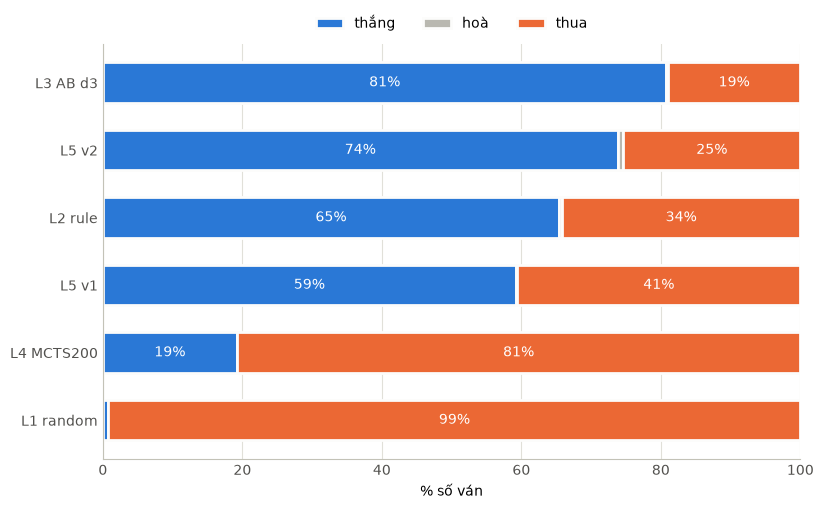

In [9]:
order = list(rank["tác tử"])[::-1]          # mạnh nhất ở trên cùng
r = rank.set_index("tác tử").loc[order]
fig, ax = plt.subplots(figsize=(9, 0.7 * len(order) + 1.2))
left = np.zeros(len(order))
for col, c in (("thắng", C_WIN), ("hoà", C_DRAW), ("thua", C_LOSS)):
    w = 100 * r[col].values / r["ván"].values
    ax.barh(order, w, left=left, color=c, edgecolor="#fcfcfb", linewidth=2, height=0.6, label=col)
    for y, (l0, ww) in enumerate(zip(left, w)):
        if ww >= 6:
            ax.text(l0 + ww / 2, y, f"{ww:.0f}%", ha="center", va="center",
                    color="white" if c != C_DRAW else INK, fontsize=10)
    left += w
ax.set_xlim(0, 100); ax.set_xlabel("% số ván"); style(ax)
ax.legend(ncol=3, frameon=False, loc="lower center", bbox_to_anchor=(0.5, 1.0))
plt.savefig(OUT_DIR / "wdl_per_agent.png", dpi=150, bbox_inches="tight"); plt.show()

### 6.22 Điểm tổng + khoảng tin cậy 95%

Chấm là điểm (thắng 1, hoà 0.5), vạch là khoảng tin cậy Wilson. Hai tác tử mà vạch chồng nhau thì chưa đủ bằng chứng để nói ai mạnh hơn. Đường đứt ở 50% = ngang ngửa.

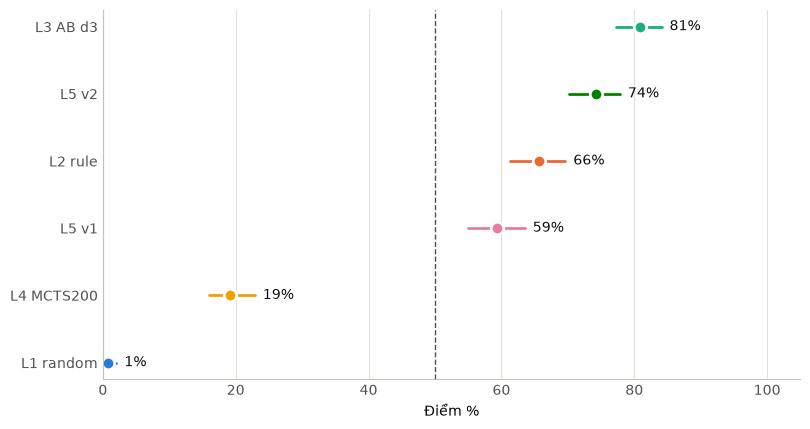

In [10]:
r = rank.iloc[::-1]
fig, ax = plt.subplots(figsize=(9, 0.6 * len(r) + 1.2))
for y, row in enumerate(r.to_dict("records")):
    n, pt, lo, hi = row["tác tử"], row["điểm %"], max(row["CI95 thấp"], 0), row["CI95 cao"]
    ax.plot([lo, hi], [y, y], color=COLOR[n], lw=2, solid_capstyle="round")
    ax.plot(pt, y, "o", color=COLOR[n], ms=9, mec="#fcfcfb", mew=2)
    ax.text(hi + 1.2, y, f"{pt:.0f}%", va="center", color=INK, fontsize=10)
ax.axvline(50, color=MUTED, ls="--", lw=1)
ax.set_yticks(range(len(r)), r["tác tử"]); ax.set_xlim(0, 105); ax.set_xlabel("Điểm %"); style(ax)
plt.savefig(OUT_DIR / "score_ci.png", dpi=150, bbox_inches="tight"); plt.show()

### 6.33 Từng cặp đối đầu

Mỗi hàng là một cặp: xanh = tác tử bên trái thắng, xám = hoà, cam = tác tử bên phải thắng. Sắp theo mức chênh lệch (cặp cân tài ở trên).

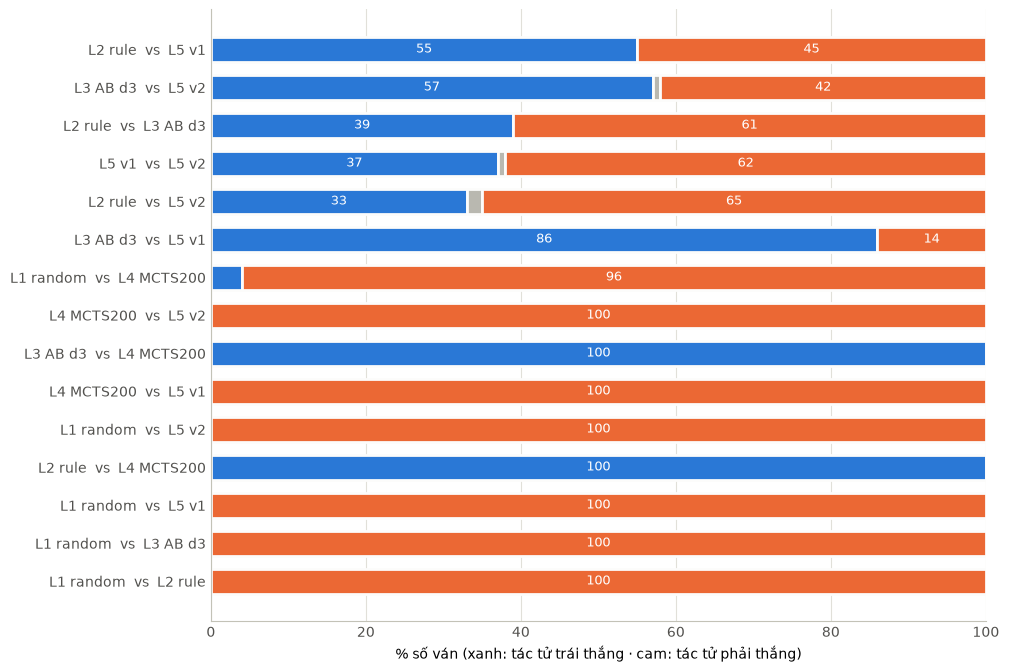

In [11]:
pr = []
for A_, B_ in pairs:
    g = games[(games.A == A_) & (games.B == B_)]
    o = np.array([outcome_for(r, A_) for r in g.itertuples()])
    pr.append({"cặp": f"{A_}  vs  {B_}", "A thắng": (o == 1).mean() * 100,
               "hoà": (o == 0.5).mean() * 100, "B thắng": (o == 0).mean() * 100})
pr = pd.DataFrame(pr)
pr = pr.assign(_d=(pr["A thắng"] - pr["B thắng"]).abs()).sort_values("_d", ascending=False).drop(columns="_d")
fig, ax = plt.subplots(figsize=(10, 0.45 * len(pr) + 1.2))
left = np.zeros(len(pr))
for col, c in (("A thắng", C_WIN), ("hoà", C_DRAW), ("B thắng", C_LOSS)):
    ax.barh(pr["cặp"], pr[col], left=left, color=c, edgecolor="#fcfcfb", linewidth=2, height=0.65)
    for y, (l0, ww) in enumerate(zip(left, pr[col])):
        if ww >= 7:
            ax.text(l0 + ww / 2, y, f"{ww:.0f}", ha="center", va="center",
                    color="white" if c != C_DRAW else INK, fontsize=9)
    left += pr[col].values
ax.set_xlim(0, 100); ax.set_xlabel("% số ván (xanh: tác tử trái thắng · cam: tác tử phải thắng)"); style(ax)
plt.savefig(OUT_DIR / "pairs_stacked.png", dpi=150, bbox_inches="tight"); plt.show()

### 6.44 Lợi thế đi trước

Cột xanh: tỉ lệ thắng khi đi trước (X); cột cam: khi đi sau (O). Nếu cột xanh luôn cao hơn cam thì đi trước có lợi, và việc chia đều bên là cần thiết.

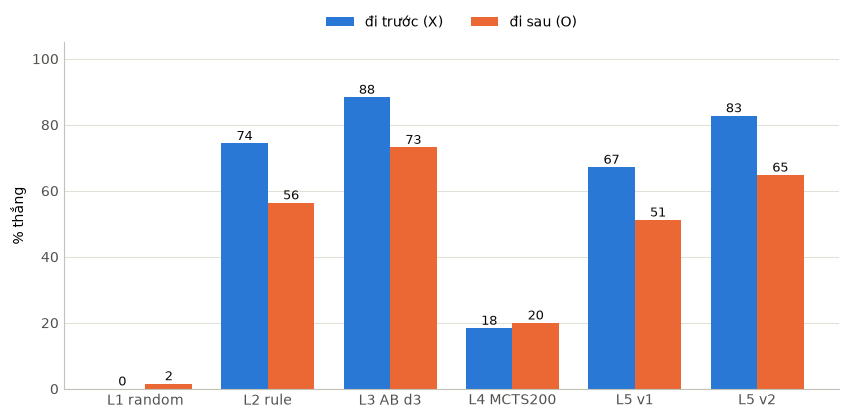

In [12]:
fig, ax = plt.subplots(figsize=(10, 4.5))
x = np.arange(len(side)); w = 0.38
b1 = ax.bar(x - w / 2, side["thắng khi đi trước %"], w, color=C_WIN, label="đi trước (X)")
b2 = ax.bar(x + w / 2, side["thắng khi đi sau %"], w, color=C_LOSS, label="đi sau (O)")
for b in (*b1, *b2):
    ax.text(b.get_x() + b.get_width() / 2, b.get_height() + 1, f"{b.get_height():.0f}",
            ha="center", color=INK, fontsize=9)
ax.set_xticks(x, side["tác tử"]); ax.set_ylabel("% thắng"); ax.set_ylim(0, 105)
style(ax, "y"); ax.legend(frameon=False, ncol=2, loc="lower center", bbox_to_anchor=(0.5, 1.0))
plt.savefig(OUT_DIR / "first_move.png", dpi=150, bbox_inches="tight"); plt.show()

### 6.55 Độ dài ván

Số nước trung bình (kể cả khai cuộc) của từng cặp. Ván ngắn thường là một bên áp đảo; ván dài là hai bên cân tài.

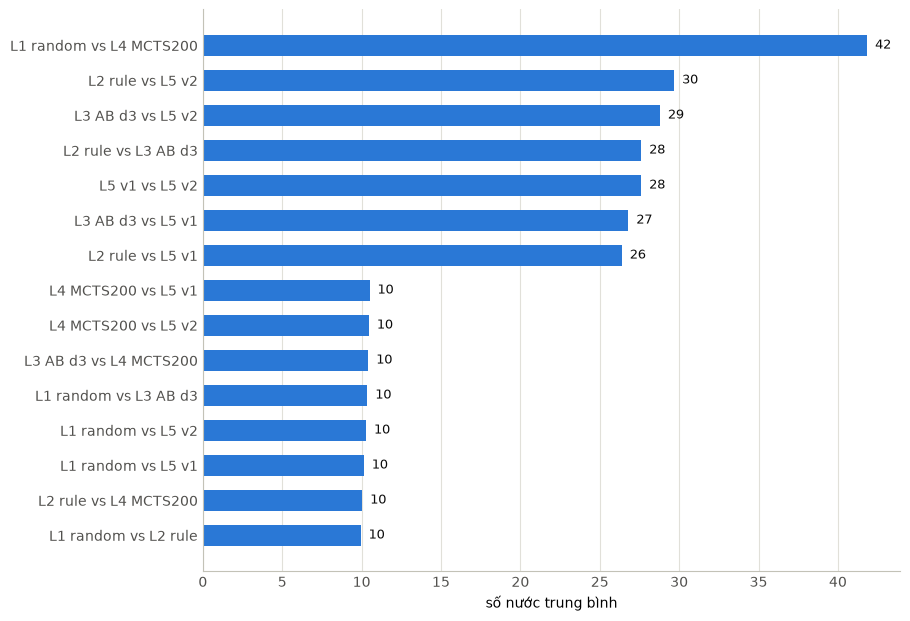

In [ ]:
pl = games.groupby("pair", sort=False).plies.mean().sort_values()
fig, ax = plt.subplots(figsize=(9, 0.42 * len(pl) + 1))
ax.barh(pl.index, pl.values, color="#2a78d6", height=0.6)
for y, v in enumerate(pl.values):
    ax.text(v + 0.5, y, f"{v:.0f}", va="center", color=INK, fontsize=9)
ax.set_xlabel("số nước trung bình"); style(ax)
plt.savefig(OUT_DIR / "plies.png", dpi=150, bbox_inches="tight"); plt.show()

### 6.66 Điểm tích luỹ theo số ván (một cặp)

Điểm của `A` khi cộng dần từng ván. Nếu đường còn lắc mạnh ở cuối thì số ván chưa đủ để kết luận.

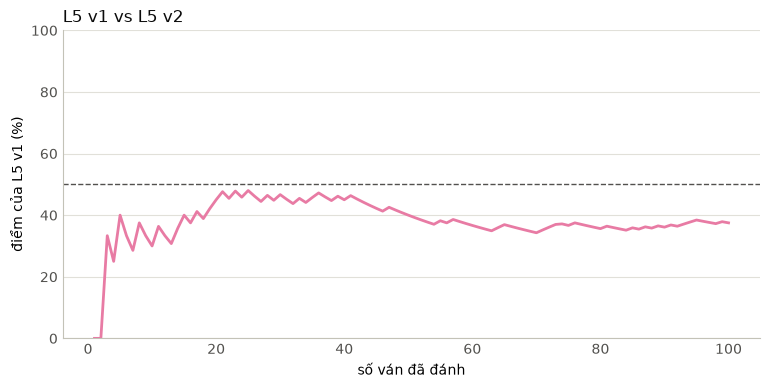

In [14]:
A, B = "L5 v1", "L5 v2"            # đổi cặp ở đây
g = games[((games.A == A) & (games.B == B)) | ((games.A == B) & (games.B == A))]
o = np.array([outcome_for(r, A) for r in g.itertuples()])
cum = np.cumsum(o) / np.arange(1, len(o) + 1) * 100
fig, ax = plt.subplots(figsize=(9, 4))
ax.plot(np.arange(1, len(o) + 1), cum, color=COLOR[A], lw=2)
ax.axhline(50, color=MUTED, ls="--", lw=1)
ax.set_ylim(0, 100); ax.set_xlabel("số ván đã đánh"); ax.set_ylabel(f"điểm của {A} (%)")
ax.set_title(f"{A} vs {B}", color=INK, loc="left"); style(ax, "y")
plt.savefig(OUT_DIR / "cumulative.png", dpi=150, bbox_inches="tight"); plt.show()